[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/07_sampling.py)

# Sampling from Gaussian Mixture Models

A fitted mixture is also a generative model. `GaussianMixture.sample` draws new points by picking a component according to the mixture weights and then sampling from that Gaussian -- and it can restrict the draw to a particular component, a shell of standard deviations, a confidence region or a ball around a chosen point using rejection sampling.

**What you'll learn**

- Draw samples from the whole mixture or from one component
- Constrain samples by standard-deviation radius or range, by confidence level, and by distance from a center point
- Why "1 standard deviation" captures far less mass in high dimensions, and how to choose a radius for a target probability

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb) and [03 -- Visualization](03_visualise.ipynb).

**See also:** the [Gaussian Mixture Model user guide](../user-guide/gaussian-mixture.md#sampling-from-the-model).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt


from tgmm import GaussianMixture, dynamic_figsize, plot_gmm

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; keep embedded figure outputs small

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Synthetic Data Generation

The synthetic dataset is generated by combining four Gaussian components:

- **Component 1:** Centered at `[0, 2]` with spherical covariance.
- **Component 2:** Centered at `[2, -2]` with spherical covariance (fewer points).
- **Component 3:** Centered at `[0, 0]` with diagonal covariance.
- **Component 4:** Centered at `[2, 2]` with full covariance.

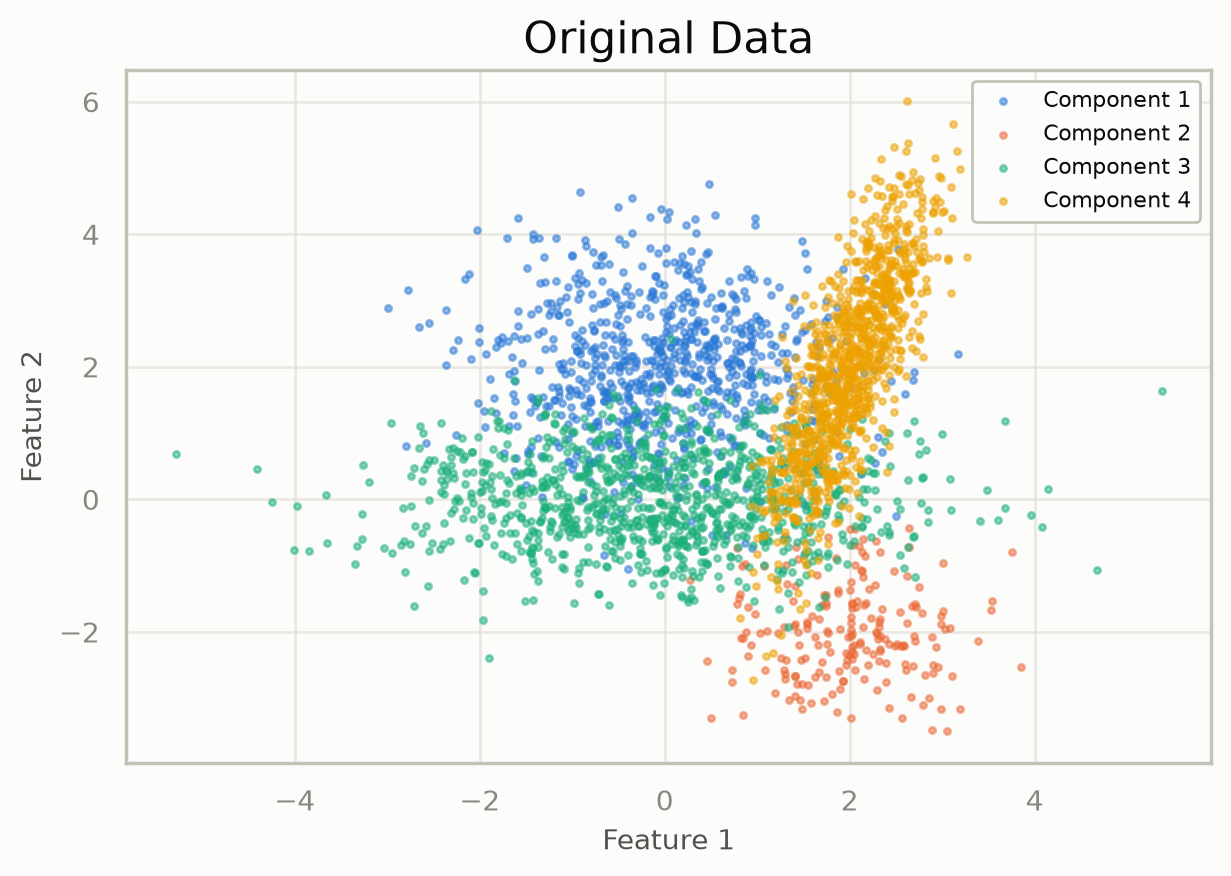

In [ ]:
_n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]), np.array([2, -2]), np.array([0, 0]), np.array([2, 2])]
covs = [1.0 * np.eye(2), 0.5 * np.eye(2), np.array([[2, 0], [0, 0.5]]), np.array([[0.2, 0.5], [0.5, 2]])]
components = []
for n, center, cov in zip(_n_samples, centers, covs):
    _samples = np.random.randn(n, 2) @ np.linalg.cholesky(cov).T + center
    components.append(_samples)  # spherical covariance
X = np.vstack(components)  # spherical covariance, fewer points
_labels = np.concatenate([i * np.ones(n) for i, n in enumerate(_n_samples)])  # diagonal covariance
legend_labels = [f'Component {i + 1}' for i in range(len(_n_samples))]  # full covariance
n_features = X.shape[1]
_n_components = len(_n_samples)
plot_gmm(X=X, true_labels=_labels, title='Original Data', legend_labels=legend_labels)
plt.gcf()

## Fitting the Gaussian Mixture Model

This section sets up the GMM with the following parameters:

- **n_components:** Number of clusters (set to 4).
- **covariance_type:** Using the 'full' covariance model.
- **Tolerance, regularization, and maximum iterations:** Set for a precise convergence.
- **Initialization:** Using random initialization with multiple random restarts (`n_init=N_INIT`: five by default, one in the fast docs build).

The GMM is then fitted to the data via the EM algorithm. After fitting, we obtain:

- **Predicted Cluster Labels:** Using the `predict` method.
- **Per-Sample Log-Likelihoods:** Using the `score_samples` method.
- **Posterior Probabilities:** For each data sample across all components.
- **New Samples:** Generated from the fitted GMM, along with the corresponding component indices.

Diagnostic information such as mean log-likelihood, convergence status, and number of iterations is printed to verify the model's performance.

In [ ]:
# Convert to tensor (if needed for further processing)
X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
_n_components = 4
gmm = GaussianMixture(n_components=_n_components, covariance_type='full', tol=1e-06, reg_covar=1e-10, max_iter=MAX_ITER, init_means='random', init_covariances='eye', n_init=N_INIT, random_state=None, warm_start=False, verbose=False, verbose_interval=10, device='cpu')
gmm.fit(X_tensor)
# Initialize the GMM
y_pred = gmm.predict(X_tensor)
log_probs = gmm.score_samples(X_tensor)
probs = gmm.predict_proba(X_tensor)
probs = probs.detach()
n_samples_to_generate = len(X)
gmm_samples, gmm_labels = gmm.sample(n_samples_to_generate)
gmm_samples = gmm_samples.detach().cpu().numpy()
gmm_labels = gmm_labels.detach().cpu().numpy()
generated_probs = gmm.predict_proba(torch.tensor(gmm_samples, dtype=torch.float32).to(device))
generated_probs = generated_probs.detach().cpu().numpy()
print('Mean per-sample log-likelihood:                        ', gmm.score(X_tensor))
print('Mean per-sample log-likelihood (torch.mean(log_probs)):', torch.mean(log_probs).item())
print('Lower bound:                                           ', gmm.lower_bound_)
for i in range(probs.shape[0]):
    assert np.isclose(torch.sum(probs[i]).item(), 1.0), f'Probabilities for sample {i} do not sum to 1'
# Fit the GMM
print('Number of iterations:                                  ', gmm.n_iter_)
# Get predictions
# Compute per-sample log-likelihoods
# Get probabilities for each sample for each component
# Generate new samples
# Compute probabilities for each generated sample
print('Converged:                                             ', gmm.converged_)

/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:880: UserWarning: Run 1: EM did not converge after 100 iterations.
  warnings.warn(
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1303: UserWarning: EM did not converge. Consider increasing max_iter or adjusting tol.
  warnings.warn(
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1817: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1776: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unrelia

Mean per-sample log-likelihood:                         -3.3676438331604004
Mean per-sample log-likelihood (torch.mean(log_probs)): -3.3676438331604004
Lower bound:                                            -3.3676438331604004
Number of iterations:                                   99
Converged:                                              False


## Sampling from Specific Components

This section shows how to sample from specific GMM components. The `sample` method accepts a `component` parameter:

- **`component=None` (default):** Samples from all components according to their mixture weights
- **`component=k`:** Samples only from component k (where k ∈ {0, 1, ..., n_components-1})

This allows us to generate samples that are guaranteed to come from a specific component, which is useful for:
- Understanding the individual component distributions
- Generating synthetic data with known ground truth labels
- Analyzing the learned parameters of each component separately

Below, we demonstrate sampling from each component individually and compare with mixed sampling.

/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unreliable.
  warnings.warn("GMM did not converge. Results may be unreliable.", UserWarning)


Component 0: Generated 40 samples, all from component 0
  Unique labels in output: [0]
  Component weight: 0.324

Component 1: Generated 40 samples, all from component 1
  Unique labels in output: [1]
  Component weight: 0.286

Component 2: Generated 40 samples, all from component 2
  Unique labels in output: [2]
  Component weight: 0.076

Component 3: Generated 40 samples, all from component 3
  Unique labels in output: [3]
  Component weight: 0.314

Mixed sampling: Generated 160 samples from all components
  Label distribution: [54 50 14 42]
  Expected distribution based on weights: [51 45 12 50]


/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)


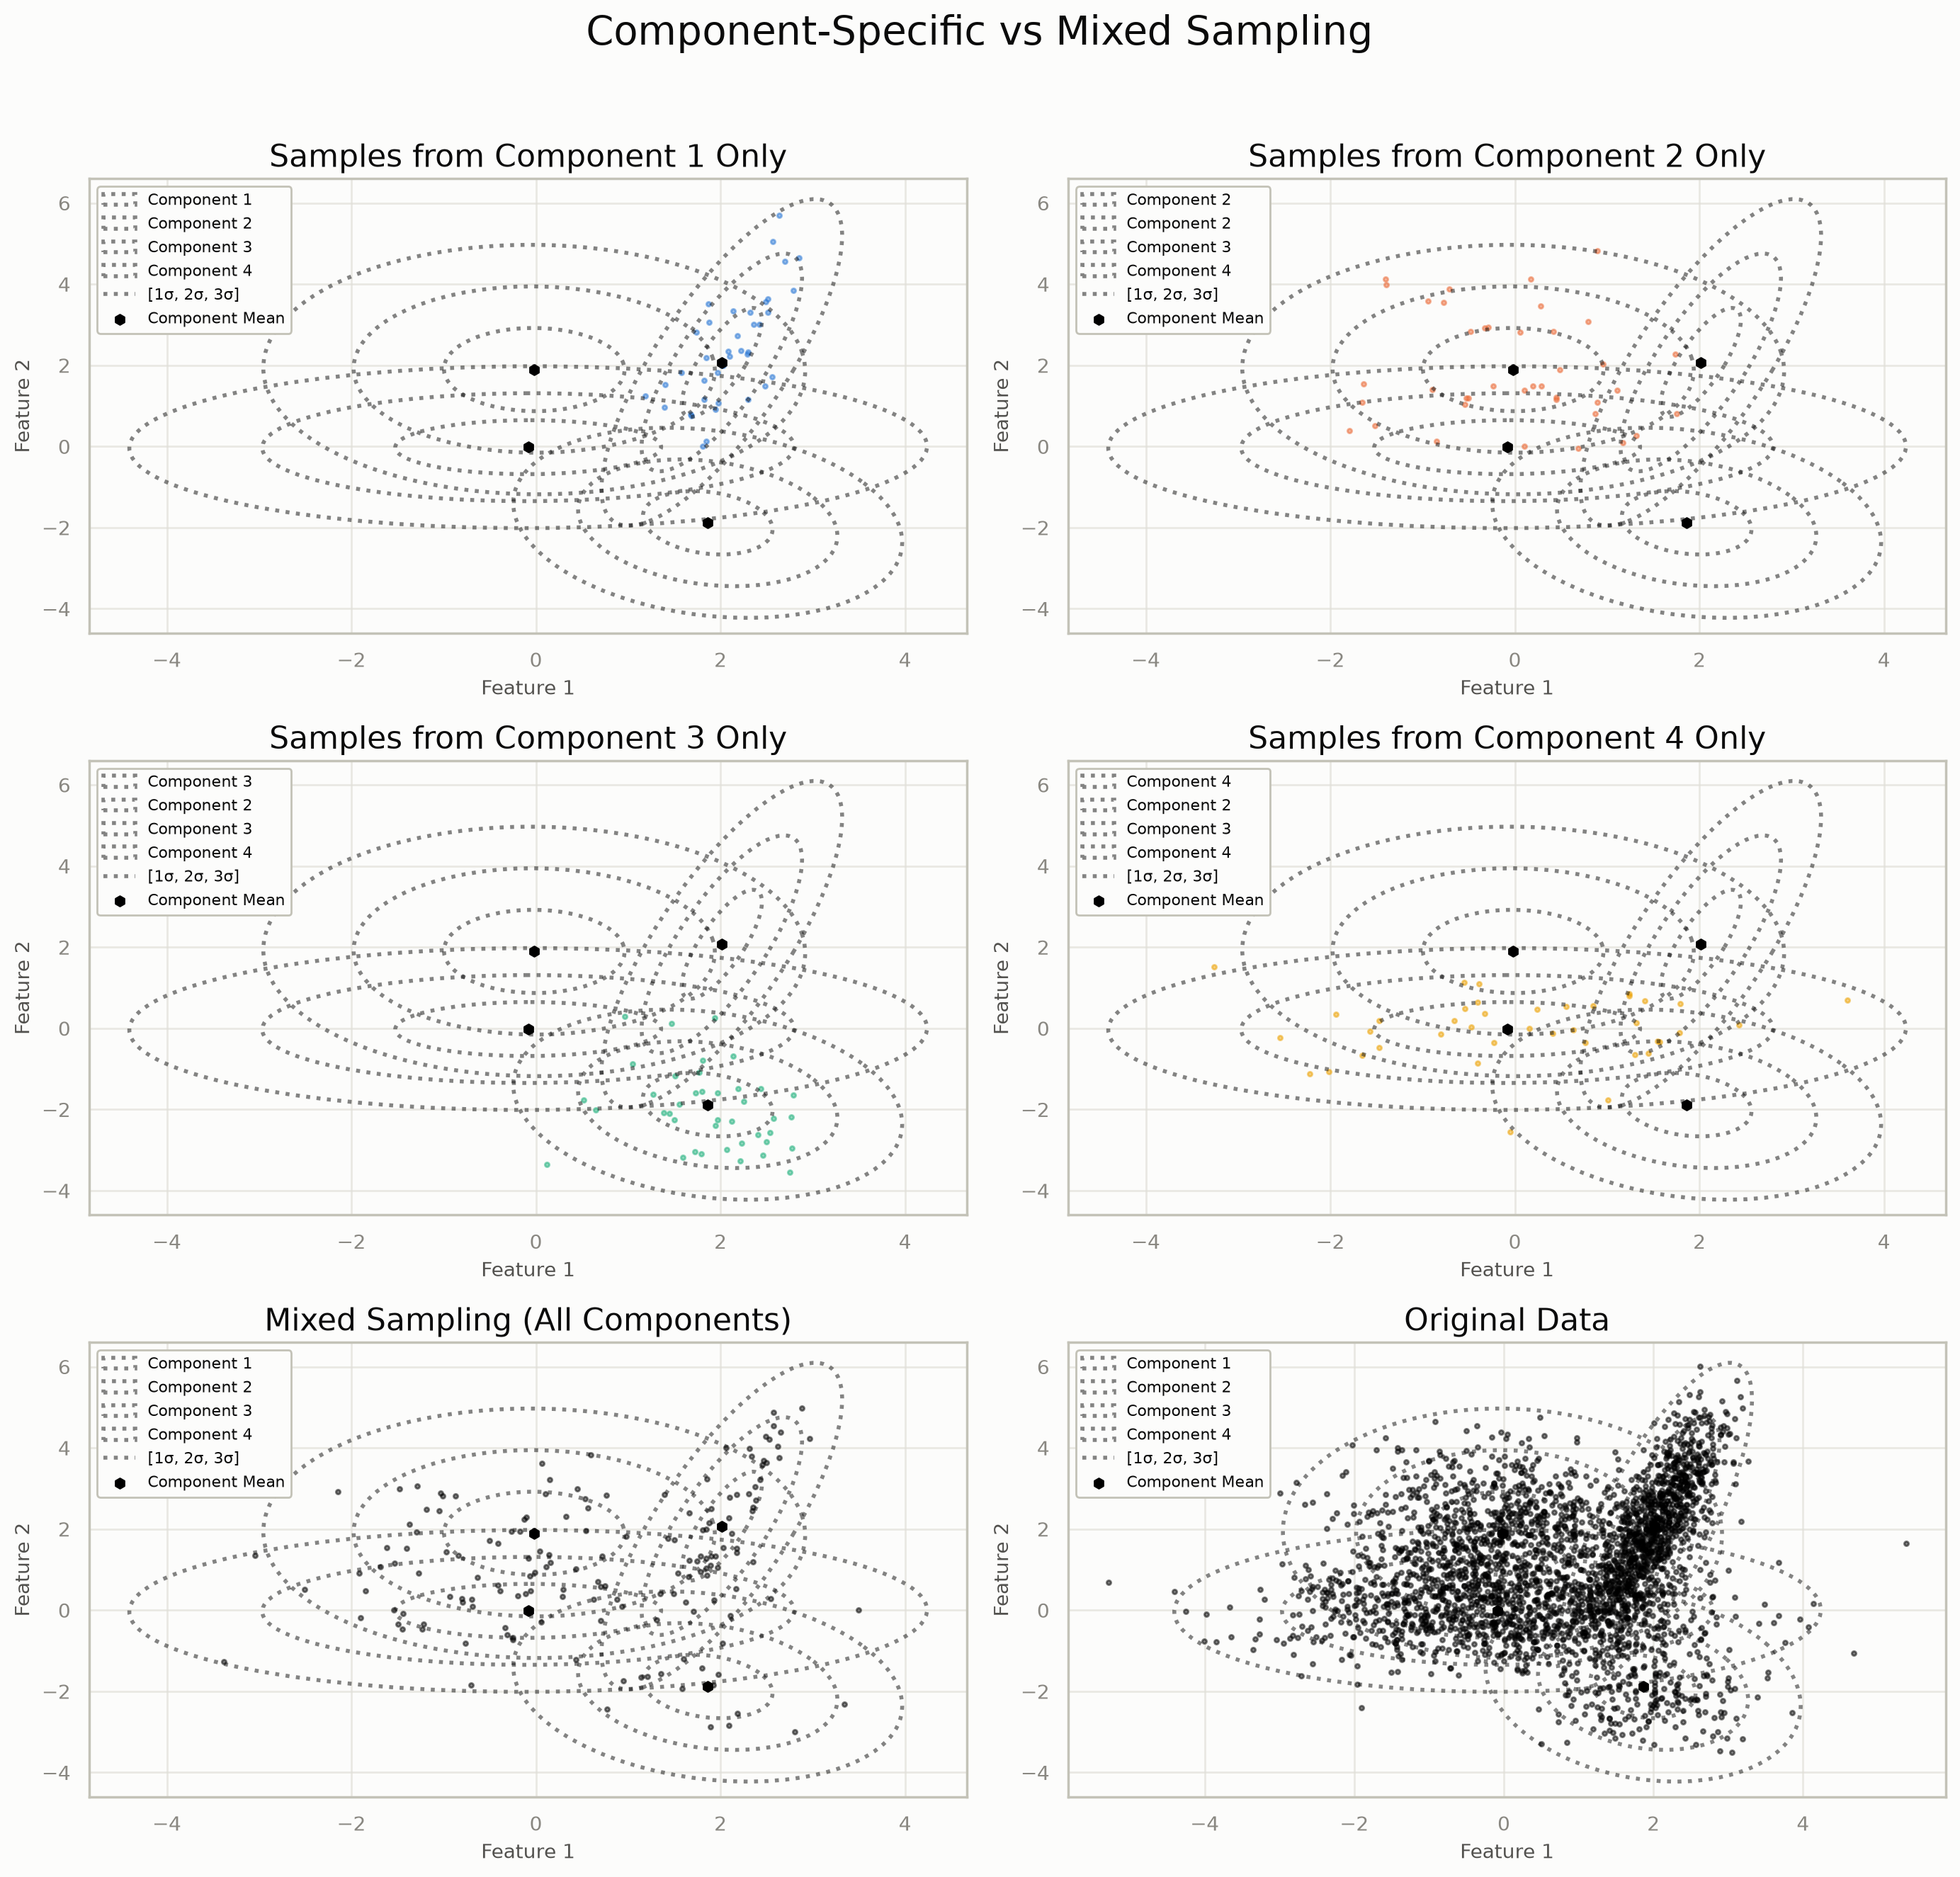

In [ ]:
# Generate samples from each component individually
_n_samples_per_component = N_DRAW
component_samples = {}
# Sample from each component separately
component_labels = {}
for _k in range(gmm.n_components):
    _samples, _labels = gmm.sample(_n_samples_per_component, component=_k)
    component_samples[_k] = _samples.detach().cpu().numpy()
    component_labels[_k] = _labels.detach().cpu().numpy()
    print(f'Component {_k}: Generated {len(_samples)} samples, all from component {_k}')
    print(f'  Unique labels in output: {np.unique(_labels.cpu().numpy())}')
    print(f'  Component weight: {gmm.weights_[_k].item():.3f}')
    print()
mixed_samples, mixed_labels = gmm.sample(_n_samples_per_component * gmm.n_components, component=None)
mixed_samples = mixed_samples.detach().cpu().numpy()
mixed_labels = mixed_labels.detach().cpu().numpy()
# Sample from all components (mixed sampling) for comparison
print(f'Mixed sampling: Generated {len(mixed_samples)} samples from all components')
print(f'  Label distribution: {np.bincount(mixed_labels)}')
print(f'  Expected distribution based on weights: {(gmm.weights_.cpu().numpy() * len(mixed_samples)).astype(int)}')
_nrows, _ncols = (3, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axs = _axs.flatten()
_colors = ['C0', 'C1', 'C2', 'C3']
# Visualize samples from each component
for _k in range(gmm.n_components):
    _ax = _axs[_k]
    plot_gmm(X=component_samples[_k], gmm=gmm, ax=_ax, title=f'Samples from Component {_k + 1} Only', legend_labels=[f'Component {_k + 1}'], ellipse_fill=False, color_by_cluster=True, point_color=_colors[_k])
_ax = _axs[4]
plot_gmm(X=mixed_samples, gmm=gmm, ax=_ax, title='Mixed Sampling (All Components)', legend_labels=[f'Component {i + 1}' for i in range(gmm.n_components)], ellipse_fill=False)
_ax = _axs[5]
# Plot individual component samples
plot_gmm(X=X, gmm=gmm, ax=_ax, title='Original Data', legend_labels=legend_labels, ellipse_fill=False)
plt.suptitle('Component-Specific vs Mixed Sampling')
plt.tight_layout(rect=[0, 0, 1, 0.96])
# Plot mixed sampling
# Plot original data for comparison
plt.gcf()

## Sampling with Standard Deviation Radius

This section shows how to sample within a specified standard deviation radius of the component means. This is useful for evaluating model quality by examining samples at different confidence levels.

The `sample` method accepts a `std_radius` parameter:
- When `std_radius=None` (default): Sample from the entire Gaussian distribution
- When `std_radius=float`: Only return samples within this many standard deviations from the component mean

This uses rejection sampling to ensure all returned samples are within the specified radius, measured using the Mahalanobis distance. This functionality is particularly valuable for:
- **Quality assessment**: Examining how samples behave at different confidence levels
- **Controlled generation**: Creating samples with known proximity to component centers
- **Outlier analysis**: Understanding the distribution of samples at various standard deviation thresholds

/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unreliable.
  warnings.warn("GMM did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unreliable.
  warnings.warn("GMM did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)


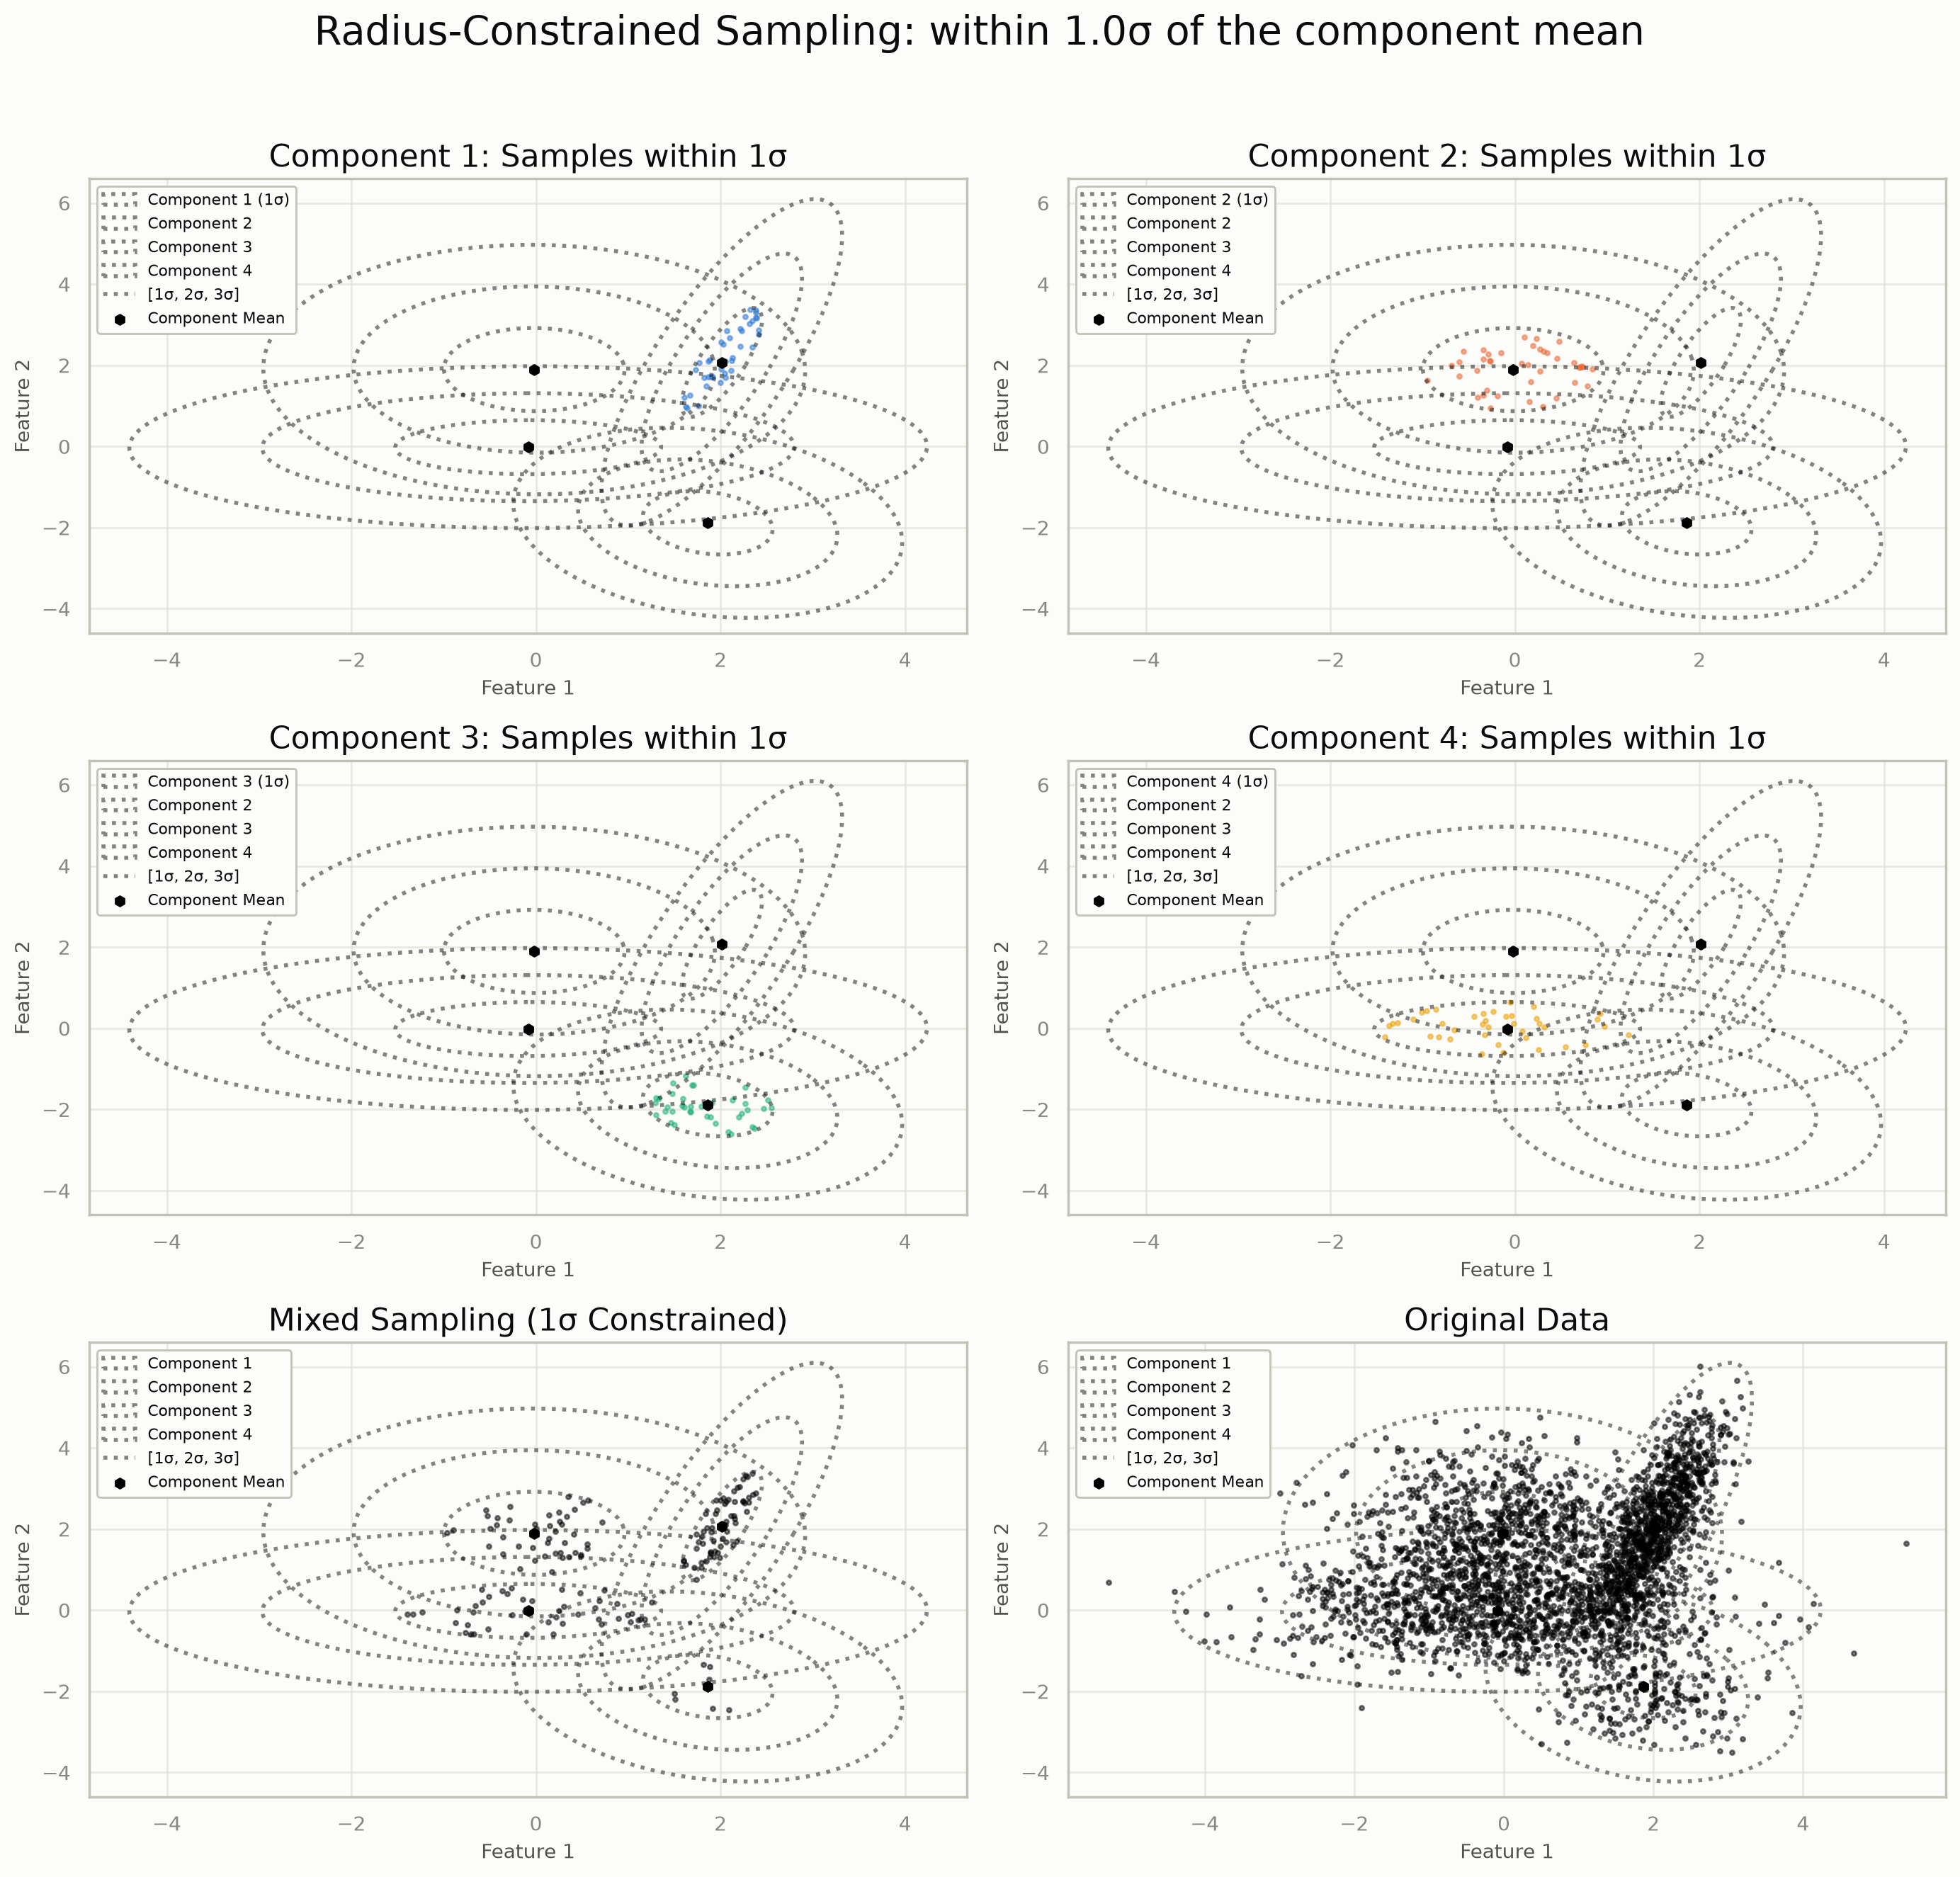

In [ ]:
_n_samples_per_component = N_DRAW
std_radius = 1.0  # Sample within 1 standard deviation
_component_samples_constrained = {}
# Sample from each component separately with radius constraint
_component_labels_constrained = {}
component_samples_unlimited = {}
component_labels_unlimited = {}
# Sample from each component separately without radius constraint (for comparison)
for _k in range(gmm.n_components):
    _samples_constrained, _labels_constrained = gmm.sample(_n_samples_per_component, component=_k, std_radius=std_radius)
    _component_samples_constrained[_k] = _samples_constrained.detach().cpu().numpy()
    _component_labels_constrained[_k] = _labels_constrained.detach().cpu().numpy()
    samples_unlimited, labels_unlimited = gmm.sample(_n_samples_per_component, component=_k)  # Constrained sampling
    component_samples_unlimited[_k] = samples_unlimited.detach().cpu().numpy()
    component_labels_unlimited[_k] = labels_unlimited.detach().cpu().numpy()
_mixed_samples_constrained, _mixed_labels_constrained = gmm.sample(_n_samples_per_component * gmm.n_components, component=None, std_radius=std_radius)
_mixed_samples_unlimited, _mixed_labels_unlimited = gmm.sample(_n_samples_per_component * gmm.n_components, component=None)
_mixed_samples_constrained = _mixed_samples_constrained.detach().cpu().numpy()  # Unlimited sampling
_mixed_labels_constrained = _mixed_labels_constrained.detach().cpu().numpy()
_mixed_samples_unlimited = _mixed_samples_unlimited.detach().cpu().numpy()
_mixed_labels_unlimited = _mixed_labels_unlimited.detach().cpu().numpy()
_nrows, _ncols = (3, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axs = _axs.flatten()
_colors = ['C0', 'C1', 'C2', 'C3']
for _k in range(gmm.n_components):
    _ax = _axs[_k]
    plot_gmm(X=_component_samples_constrained[_k], gmm=gmm, ax=_ax, title=f'Component {_k + 1}: Samples within 1σ', legend_labels=[f'Component {_k + 1} (1σ)'], ellipse_fill=False, color_by_cluster=False, point_color=_colors[_k])
_ax = _axs[4]
plot_gmm(X=_mixed_samples_constrained, gmm=gmm, ax=_ax, title=f'Mixed Sampling (1σ Constrained)', legend_labels=[f'Component {i + 1}' for i in range(gmm.n_components)], ellipse_fill=False)
# Visualize samples: constrained vs unlimited
_ax = _axs[5]
plot_gmm(X=X, gmm=gmm, ax=_ax, title='Original Data', legend_labels=legend_labels, ellipse_fill=False)
plt.suptitle(f'Radius-Constrained Sampling: within {std_radius}σ of the component mean')
plt.tight_layout(rect=[0, 0, 1, 0.96])
# Plot individual component samples (constrained)
# Plot mixed sampling comparison (constrained)
# Plot original data for comparison
plt.gcf()

## Standard-Deviation Ranges, Confidence Regions and Outliers

Besides a single radius, `sample` accepts several other rejection-sampling constraints, all measured with the Mahalanobis distance to the component mean:

- **`std_range=(low, high)`**: only samples whose distance lies in the shell between `low` and `high` standard deviations (use `float('inf')` for an open upper end, i.e. outliers).
- **`confidence=p`**: only samples inside the central region containing probability mass $p$ (internally $\chi^2_d$-based, see the note on dimensionality below); `confidence_range=(p_low, p_high)` selects a shell by probability mass.
- **`max_attempts_per_sample`**: rejection sampling can need many draws for a thin or far-out region; raise this when the constraint is very restrictive.

Below, each component gets a different constraint: a 2-3σ shell, a 1-2σ shell, the 95% confidence region, and the >3σ tail.

/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unreliable.
  warnings.warn("GMM did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)


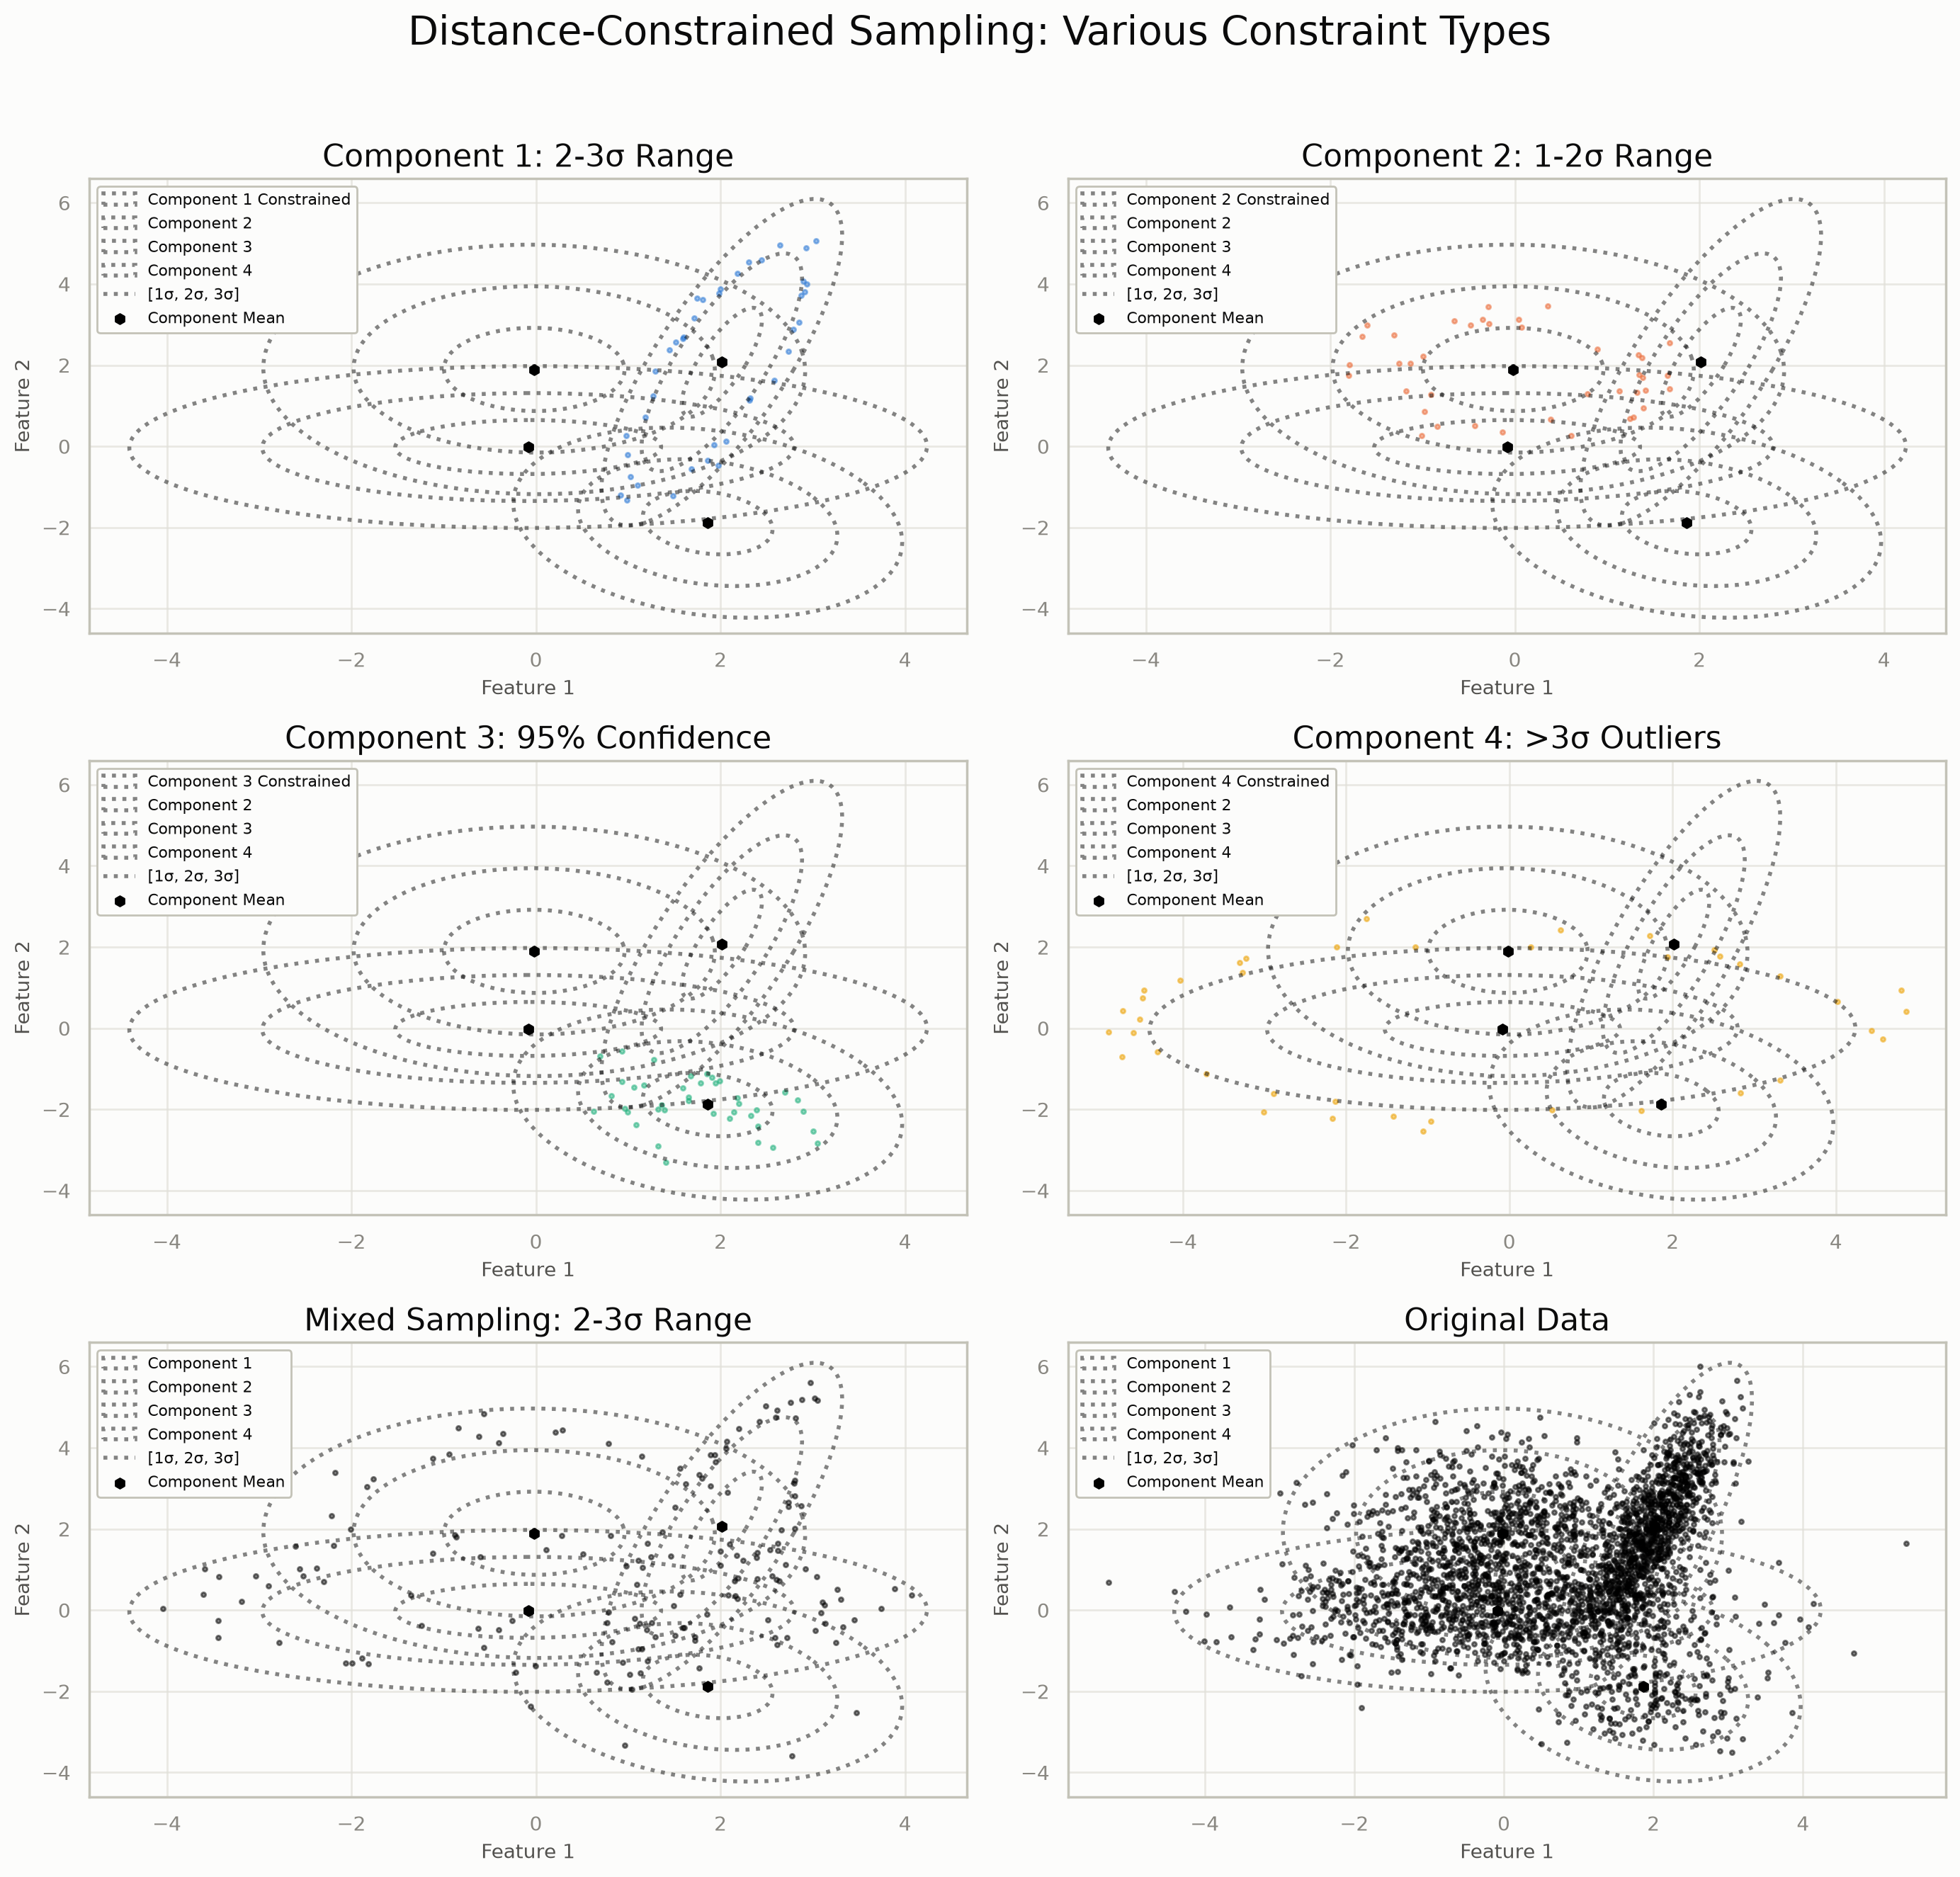

In [ ]:
_n_samples_per_component = N_DRAW
_component_samples_constrained = {}
# Sample from each component separately with different constraints
_component_labels_constrained = {}
_samples_constrained, _labels_constrained = gmm.sample(_n_samples_per_component, component=0, std_range=[2, 3])
_component_samples_constrained[0] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[0] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples_per_component, component=1, std_range=[1, 2])
_component_samples_constrained[1] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[1] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples_per_component, component=2, confidence=0.95)
_component_samples_constrained[2] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[2] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples_per_component, component=3, std_range=[3, float('inf')], max_attempts_per_sample=5000)
_component_samples_constrained[3] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[3] = _labels_constrained.detach().cpu().numpy()
_mixed_samples_constrained, _mixed_labels_constrained = gmm.sample(_n_samples_per_component * gmm.n_components, component=None, std_range=[2, 3])
_mixed_samples_unlimited, _mixed_labels_unlimited = gmm.sample(_n_samples_per_component * gmm.n_components, component=None)
_mixed_samples_constrained = _mixed_samples_constrained.detach().cpu().numpy()
_mixed_labels_constrained = _mixed_labels_constrained.detach().cpu().numpy()
_mixed_samples_unlimited = _mixed_samples_unlimited.detach().cpu().numpy()
_mixed_labels_unlimited = _mixed_labels_unlimited.detach().cpu().numpy()
_nrows, _ncols = (3, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axs = _axs.flatten()
_colors = ['C0', 'C1', 'C2', 'C3']
_constraint_titles = ['Component 1: 2-3σ Range', 'Component 2: 1-2σ Range', 'Component 3: 95% Confidence', 'Component 4: >3σ Outliers']
for _k in range(len(_component_samples_constrained)):
    _ax = _axs[_k]
# Visualize samples: constrained vs unlimited
    plot_gmm(X=_component_samples_constrained[_k], gmm=gmm, ax=_ax, title=_constraint_titles[_k], legend_labels=[f'Component {_k + 1} Constrained'], ellipse_fill=False, color_by_cluster=False, point_color=_colors[_k])
_ax = _axs[4]
plot_gmm(X=_mixed_samples_constrained, gmm=gmm, ax=_ax, title='Mixed Sampling: 2-3σ Range', legend_labels=[f'Component {i + 1}' for i in range(gmm.n_components)], ellipse_fill=False)
_ax = _axs[5]
plot_gmm(X=X, gmm=gmm, ax=_ax, title='Original Data', legend_labels=legend_labels, ellipse_fill=False)
plt.suptitle('Distance-Constrained Sampling: Various Constraint Types')
# Plot individual component samples (constrained)
plt.tight_layout(rect=[0, 0, 1, 0.96])
# Plot mixed sampling comparison (constrained)
# Plot original data for comparison
plt.gcf()

## Sampling Around a Fixed Center Point

`center_point` and `center_radius` restrict samples to a Euclidean ball around an arbitrary location, independent of any component's own covariance -- for example to generate synthetic data near a point of interest. The red circle in each panel is the constraint.

/home/runner/work/tgmm/tgmm/tgmm/gmm.py:3728: UserWarning: GMM did not converge. Results may be unreliable.
  warnings.warn("GMM did not converge. Results may be unreliable.", UserWarning)
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)


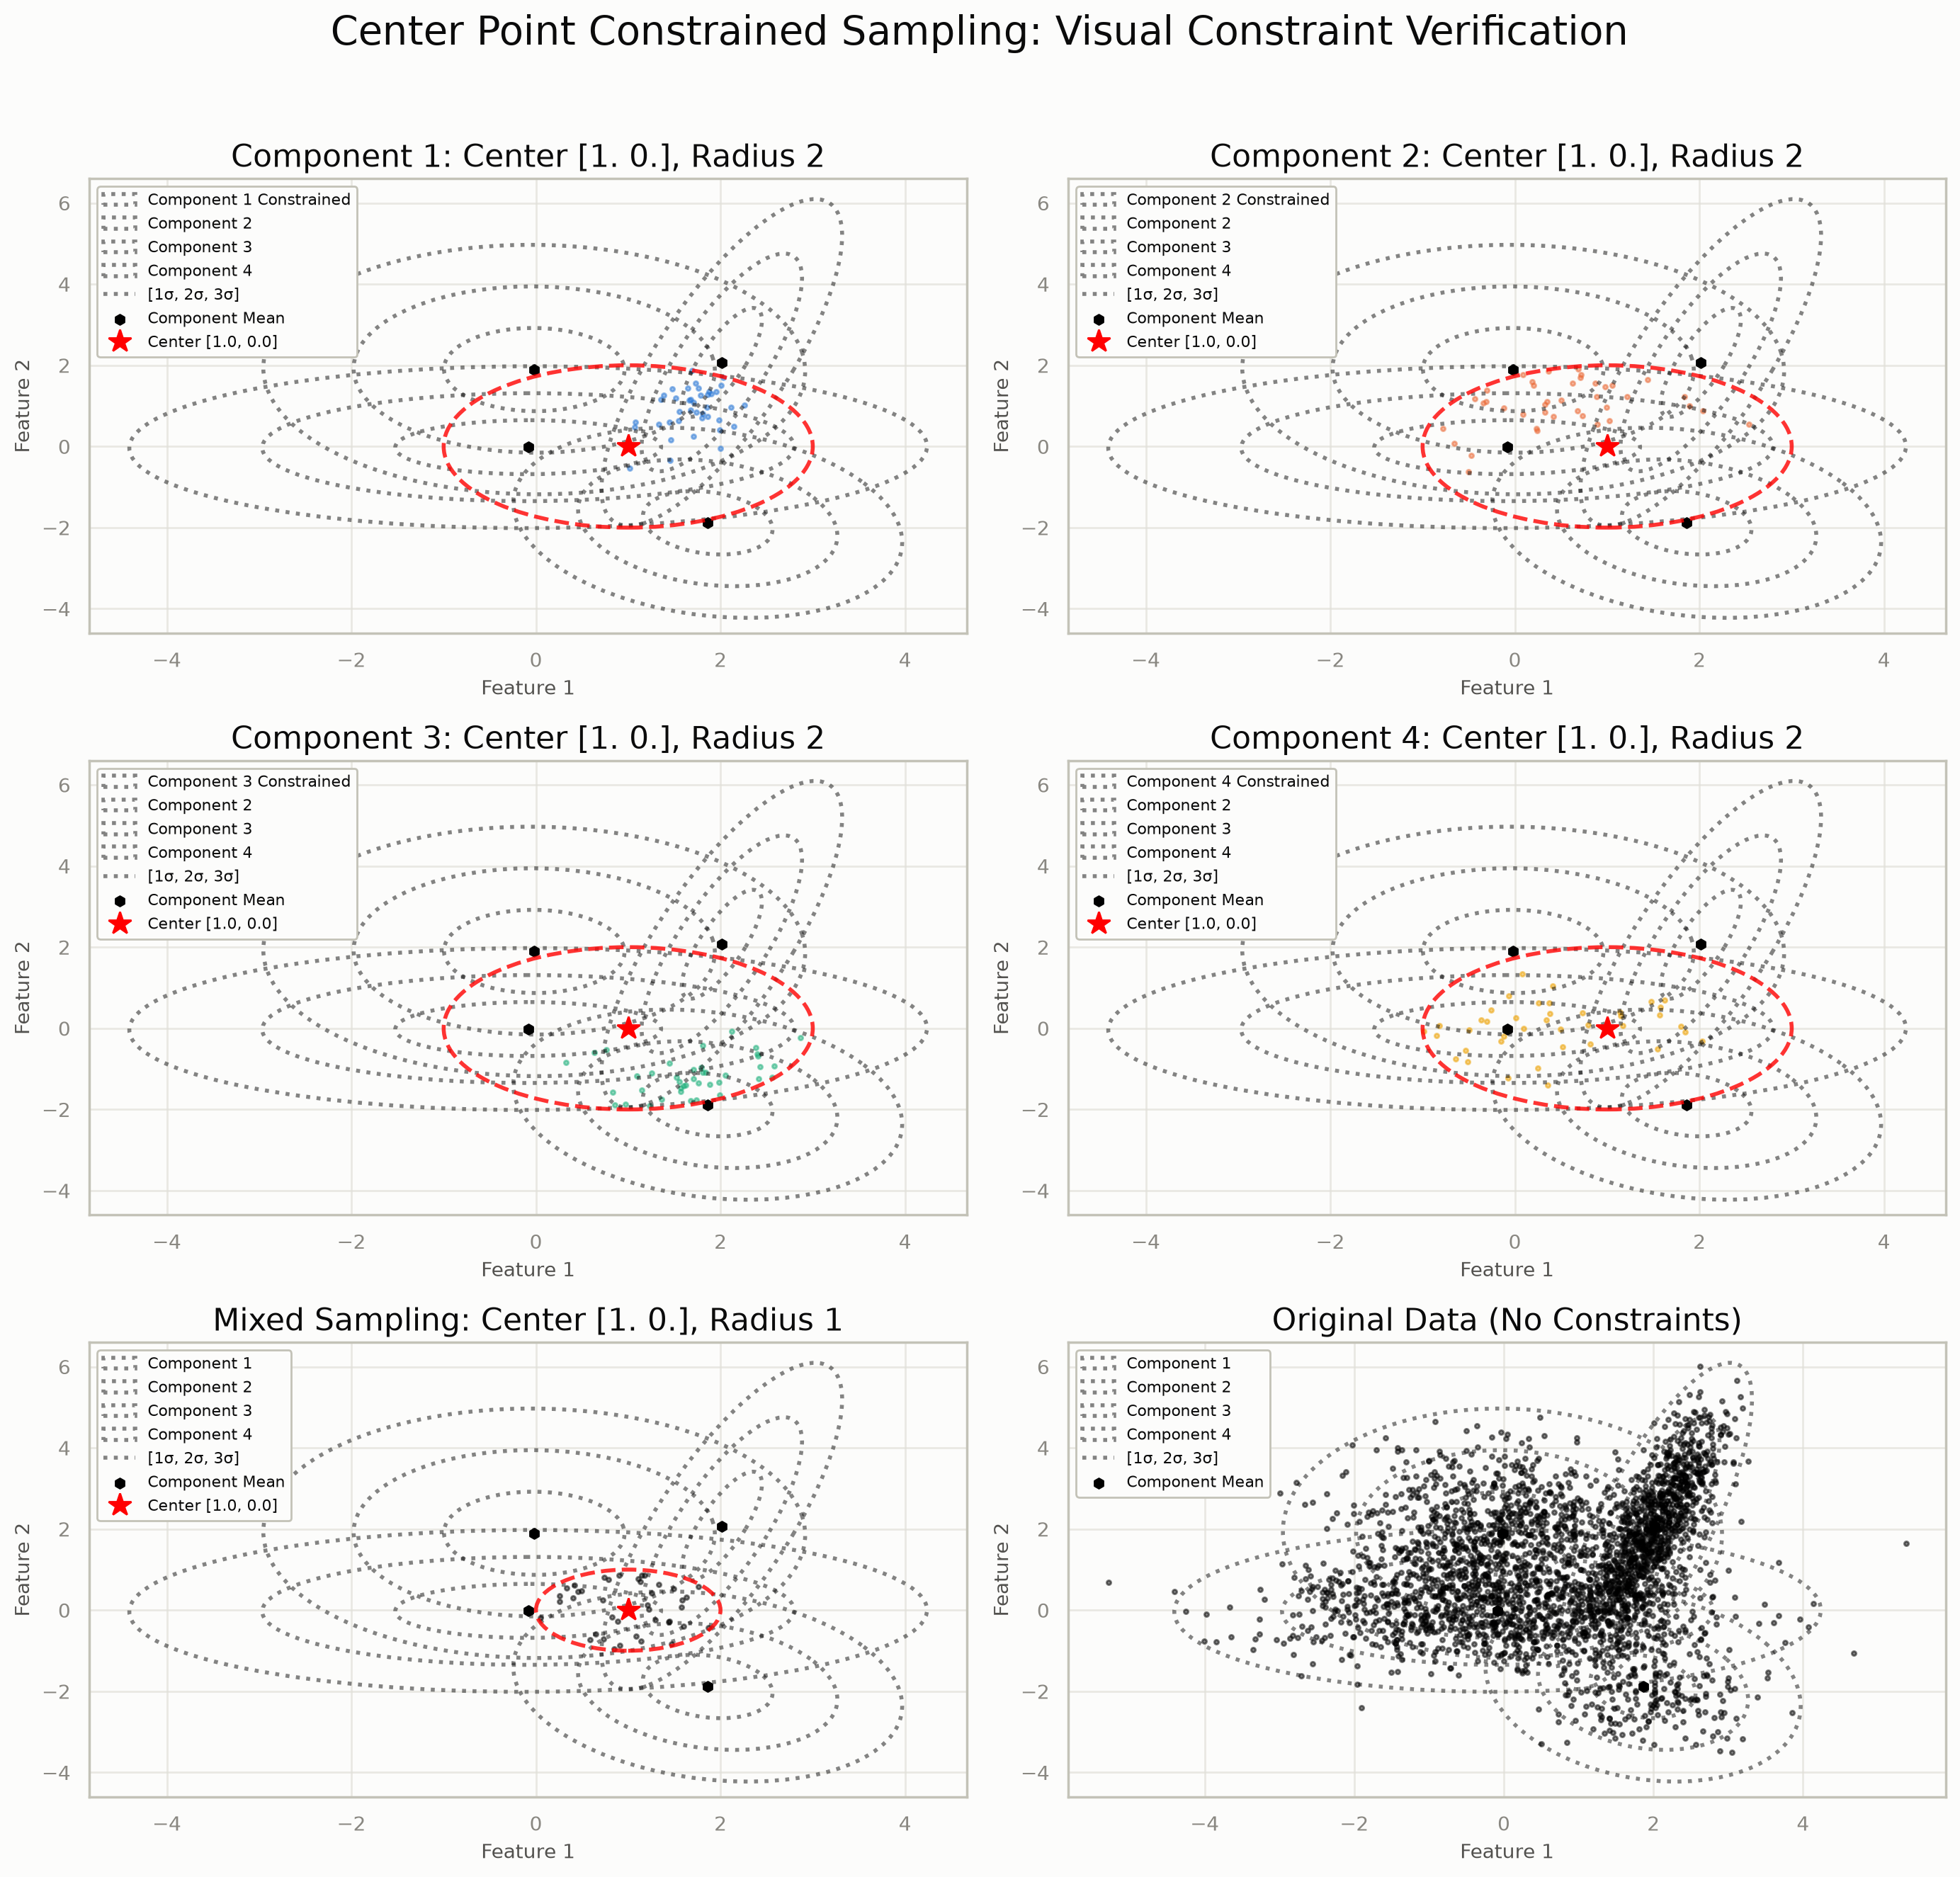

In [ ]:
_n_samples = N_DRAW
center_point = torch.tensor([1.0, 0.0])
# Define the center point and radius for visualization
center_radius = 2
_component_samples_constrained = {}
_component_labels_constrained = {}
# Sample from each component separately with different constraints
_samples_constrained, _labels_constrained = gmm.sample(_n_samples, component=0, center_point=center_point, center_radius=center_radius, max_attempts_per_sample=10000)
_component_samples_constrained[0] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[0] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples, component=1, center_point=center_point, center_radius=center_radius, max_attempts_per_sample=10000)
_component_samples_constrained[1] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[1] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples, component=2, center_point=center_point, center_radius=center_radius, max_attempts_per_sample=10000)
_component_samples_constrained[2] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[2] = _labels_constrained.detach().cpu().numpy()
_samples_constrained, _labels_constrained = gmm.sample(_n_samples, component=3, center_point=center_point, center_radius=center_radius, max_attempts_per_sample=10000)
_component_samples_constrained[3] = _samples_constrained.detach().cpu().numpy()
_component_labels_constrained[3] = _labels_constrained.detach().cpu().numpy()
_mixed_samples_constrained, _mixed_labels_constrained = gmm.sample(_n_samples, component=None, center_point=center_point, center_radius=1, max_attempts_per_sample=10000)
_mixed_samples_unlimited, _mixed_labels_unlimited = gmm.sample(_n_samples, component=None)
_mixed_samples_constrained = _mixed_samples_constrained.detach().cpu().numpy()
_mixed_labels_constrained = _mixed_labels_constrained.detach().cpu().numpy()
_mixed_samples_unlimited = _mixed_samples_unlimited.detach().cpu().numpy()
_mixed_labels_unlimited = _mixed_labels_unlimited.detach().cpu().numpy()
center_np = center_point.numpy()
_nrows, _ncols = (3, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axs = _axs.flatten()
_colors = ['C0', 'C1', 'C2', 'C3']
_constraint_titles = [f'Component 1: Center {center_np}, Radius {center_radius}', f'Component 2: Center {center_np}, Radius {center_radius}', f'Component 3: Center {center_np}, Radius {center_radius}', f'Component 4: Center {center_np}, Radius {center_radius}']
for _k in range(len(_component_samples_constrained)):
    _ax = _axs[_k]
# Convert center point to numpy for plotting
    plot_gmm(X=_component_samples_constrained[_k], gmm=gmm, ax=_ax, title=_constraint_titles[_k], legend_labels=[f'Component {_k + 1} Constrained'], ellipse_fill=False, color_by_cluster=False, point_color=_colors[_k])
    circle = plt.Circle(center_np, center_radius, fill=False, color='red', linewidth=2, linestyle='--', alpha=0.8)
# Visualize samples: constrained vs unlimited
    _ax.add_patch(circle)
    _ax.plot(center_np[0], center_np[1], 'r*', markersize=12, label=f'Center [{center_np[0]}, {center_np[1]}]')
    _ax.legend()
_ax = _axs[4]
plot_gmm(X=_mixed_samples_constrained, gmm=gmm, ax=_ax, title=f'Mixed Sampling: Center {center_np}, Radius {1}', legend_labels=[f'Component {i + 1}' for i in range(gmm.n_components)], ellipse_fill=False)
circle_mixed = plt.Circle(center_np, 1, fill=False, color='red', linewidth=2, linestyle='--', alpha=0.8)
# Plot individual component samples (constrained)
_ax.add_patch(circle_mixed)
_ax.plot(center_np[0], center_np[1], 'r*', markersize=12, label=f'Center [{center_np[0]}, {center_np[1]}]')
_ax.legend()
_ax = _axs[5]
plot_gmm(X=X, gmm=gmm, ax=_ax, title='Original Data (No Constraints)', legend_labels=legend_labels, ellipse_fill=False)
_ax.legend()
plt.suptitle('Center Point Constrained Sampling: Visual Constraint Verification')
plt.tight_layout(rect=[0, 0, 1, 0.96])
# Plot mixed sampling comparison (constrained)
# Add center point constraint visualization to mixed plot
# Plot original data for comparison
plt.gcf()

## **Important**: The Curse of Dimensionality in GMM Sampling

**Why does `std_radius=1.0` fail in high-dimensional spaces?**

In high-dimensional spaces, the concept of "1 standard deviation" behaves very differently than in 1D or 2D:

### Mathematical Explanation
- **1D**:       ~68.27% of samples fall within 1 std deviation
- **2D**:       ~39.35% of samples fall within 1 std deviation
- **10D**:      ~0.02% of samples fall within 1 std deviation

For a $d$-dimensional standard multivariate Gaussian distribution $\mathbf{X} \sim \mathcal{N}(0, I)$, the squared distance from the origin follows a chi-square distribution:

$$
\|\mathbf{X}\|^2 = X_1^2 + X_2^2 + \cdots + X_d^2 \sim \chi^2(d)
$$

The probability that a sample lies within radius $r$ of the origin is:

$$
P(\|\mathbf{X}\| \leq r) = P(\chi^2(d) \leq r^2)
$$

#### **Table: Percentage of Samples Within $k$ Standard Deviations**

| Dimension | Within 1 std ($r=1$) | Within 2 std ($r=2$) | Radius for 95% ($r_{95}$) |
|-----------|----------------------|----------------------|--------------------------|
| 1         | 68.27%               | 95.45%               | $r \approx 1.96$         |
| 2         | 39.35%               | 86.47%               | $r \approx 2.45$         |
| 3         | 19.87%               | 73.85%               | $r \approx 2.80$         |
| 5         | 3.74%                | 45.06%               | $r \approx 3.33$         |
| 10        | 0.02%                | 5.27%                | $r \approx 4.28$         |

### How to Find the Ideal Radius for a Given Percentage

To find the radius $r$ that contains a desired percentage $p$ of samples from a $d$-dimensional standard Gaussian, you need to solve:

$$
P(\|\mathbf{X}\| \leq r) = p
$$

Since $ \|\mathbf{X}\|^2 \sim \chi^2(d) $, this is equivalent to:

$$
P(\chi^2(d) \leq r^2) = p
$$

So, $ r^2 $ is the $p$-th quantile of the chi-square distribution with $d$ degrees of freedom. Denote this quantile as $q_p$:

$$
r = \sqrt{q_p}
$$

where $q_p$ solves $F_{\chi^2(d)}(q_p) = p$, with $F_{\chi^2(d)}$ being the cumulative distribution function (CDF).

#### **Exact Formula:**

$$
r_p = \sqrt{F_{\chi^2(d)}^{-1}(p)}
$$

where $F_{\chi^2(d)}^{-1}$ is the inverse CDF (quantile function) of the chi-square distribution.

**Example:**

- For 95% of samples ($p=0.95$), the ideal radius is:

$$
r_{95} = \sqrt{F_{\chi^2(d)}^{-1}(0.95)}
$$

**In Python, you can compute this with:**

```python
from scipy.stats import chi2
d = 10  # for example
desired_p = 0.95
r_95 = (chi2.ppf(desired_p, d))**0.5
```

## Summary

- `sample(n)` draws from the whole mixture; `component=k` restricts the draw to one component.
- `std_radius`, `std_range` and `confidence` / `confidence_range` constrain samples by Mahalanobis distance; `center_point` / `center_radius` constrain them to a ball around any location.
- Constraints are enforced by rejection sampling, so very restrictive regions need a larger `max_attempts_per_sample`.
- In $d$ dimensions the squared Mahalanobis distance is $\chi^2_d$-distributed, so use a confidence level (or the $\chi^2$ quantile radius) rather than a fixed number of standard deviations.

**Next:** [08 -- PCA Plotting](08_pca_plotting.ipynb) for visualizing high-dimensional samples, or [11 -- Dirichlet Process Mixtures](11_dpgmm.ipynb).